Praktikum 4 - Ekstraksi fitur data tidak terstruktur (citra).

Fitur utama sesuai modul: histogram 256 bin per kanal R, G, B.
Tambahan: statistik kanal, GLCM (contrast, dissimilarity, homogeneity,
energy, correlation), dan HOG untuk bentuk/tekstur.
Output: output/histogram_rgb.png, output/hog.png, output/fitur_citra.csv

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("ekstraksi_fitur_citra.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js03-ektraksi-fitur\praktikum-4


In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib

import matplotlib.pyplot as plt
from PIL import Image
from skimage.color import rgb2gray
from skimage.feature import graycomatrix, graycoprops, hog
from skimage.transform import resize

HERE = Path(__file__).resolve().parent
DATA = HERE.parent / "data"
OUT = HERE / "output"
OUT.mkdir(exist_ok=True)

In [3]:
# Langkah 1 - load image
img = Image.open(DATA / "Lenna_(test_image).png")
print(f"mode={img.mode} size={img.size} format={img.format}")

mode=RGB size=(512, 512) format=PNG


In [4]:
# Langkah 2 - ekstraksi fitur histogram per kanal
r, g, b = img.split()
hist = {name: np.array(ch.histogram()) for name, ch in
        (("R", r), ("G", g), ("B", b))}
print(f"len(r.histogram()) = {len(r.histogram())}")
print(f"histogram R (256 bin) = {r.histogram()}")

arr = np.array(img)
for name, h in hist.items():
    bins = np.arange(256)
    mean_bin = np.dot(bins, h) / h.sum()
    std_bin = np.sqrt(np.dot((bins - mean_bin) ** 2, h) / h.sum())
    print(f"kanal {name}: sum={h.sum()} (={img.size[0] * img.size[1]}) "
          f"mean_bin={mean_bin:.4f} std={std_bin:.4f} max_bin={h.argmax()}")

len(r.histogram()) = 256
histogram R (256 bin) = [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 1, 1, 1, 8, 6, 10, 9, 20, 37, 32, 41, 53, 74, 103, 132, 179, 193, 242, 238, 336, 386, 404, 483, 607, 628, 771, 785, 1001, 1016, 1177, 1269, 1332, 1446, 1487, 1457, 1574, 1585, 1591, 1557, 1569, 1660, 1648, 1420, 1559, 1418, 1384, 1319, 1342, 1156, 1120, 955, 969, 828, 782, 752, 737, 719, 700, 628, 673, 587, 617, 610, 592, 557, 593, 552, 566, 582, 559, 571, 520, 664, 650, 618, 730, 594, 667, 675, 685, 771, 715, 667, 740, 744, 766, 765, 772, 817, 817, 744, 806, 760, 777, 812, 797, 799, 861, 814, 910, 907, 918, 888, 1011, 879, 996, 912, 952, 884, 1074, 977, 1073, 1040, 1216, 1250, 1403, 1534, 1639, 1682, 1776, 1874, 1769, 1582, 1743, 1441, 1477, 1483, 1409, 1437, 1449, 1389, 1479, 1592, 1655, 1657, 1666, 1857, 1896, 1813, 1979, 1814, 1956, 1928, 2055, 2012, 2303, 2333, 2670,

In [5]:
# ---- tambahan: GLCM pada citra grayscale 8 level ----
gray = (rgb2gray(arr) * 255).astype(np.uint8)
gray_q = (gray // 32).astype(np.uint8)  # kuantisasi 8 level (0-7)
glcm = graycomatrix(gray_q, distances=[1], angles=[0, np.pi / 4, np.pi / 2,
                                                   3 * np.pi / 4],
                    levels=8, symmetric=True, normed=True)
props = ["contrast", "dissimilarity", "homogeneity", "energy", "correlation"]
glcm_feat = {}
for p in props:
    vals = graycoprops(glcm, p)[0]
    glcm_feat[p] = vals.mean()
print("\n=== GLCM (rata-rata 4 arah, kuantisasi 8 level) ===")
for k, v in glcm_feat.items():
    print(f"{k:14s} = {v:.6f}")


=== GLCM (rata-rata 4 arah, kuantisasi 8 level) ===
contrast       = 0.240320
dissimilarity  = 0.201329
homogeneity    = 0.903151
energy         = 0.353980
correlation    = 0.950095


In [6]:
# ---- tambahan: HOG ----
small = resize(gray, (128, 128), anti_aliasing=True)
hog_vec = hog(small, orientations=9, pixels_per_cell=(16, 16),
              cells_per_block=(2, 2), feature_vector=True)
print(f"\nHOG: dimensi = {hog_vec.shape[0]} "
      f"(9 orientasi, sel 16x16, blok 2x2 pada 128x128)")
print(f"HOG min/max/mean = {hog_vec.min():.6f}/{hog_vec.max():.6f}/"
      f"{hog_vec.mean():.6f}")


HOG: dimensi = 1764 (9 orientasi, sel 16x16, blok 2x2 pada 128x128)
HOG min/max/mean = 0.000731/0.381542/0.128252


In [7]:
# ---- simpan seluruh fitur sebagai satu vektor ----
feats = {}
for name, h in hist.items():
    for i, v in enumerate(h):
        feats[f"hist_{name}_{i}"] = int(v)
for name, v in zip(("mean", "std", "min", "max"), (
        arr.reshape(-1, 3).mean(0), arr.reshape(-1, 3).std(0),
        arr.reshape(-1, 3).min(0), arr.reshape(-1, 3).max(0))):
    for ch, val in zip("RGB", np.atleast_1d(v)):
        feats[f"{name}_{ch}"] = float(val)
for k, v in glcm_feat.items():
    feats[f"glcm_{k}"] = float(v)
for i, v in enumerate(hog_vec):
    feats[f"hog_{i}"] = float(v)

df = pd.DataFrame([feats])
df.to_csv(OUT / "fitur_citra.csv", index=False)
print(f"\nTotal fitur = {df.shape[1]} kolom -> output/fitur_citra.csv")
print(f"  histogram RGB : {3 * 256}")
print(f"  statistik     : {len([c for c in df.columns if c.split('_')[0] in ('mean','std','min','max')])}")
print(f"  GLCM          : {len(glcm_feat)}")
print(f"  HOG           : {hog_vec.shape[0]}")


Total fitur = 2549 kolom -> output/fitur_citra.csv


  histogram RGB : 768
  statistik     : 12
  GLCM          : 5
  HOG           : 1764


grafik -> output/histogram_rgb.png, output/hog.png

Selesai praktikum 4.


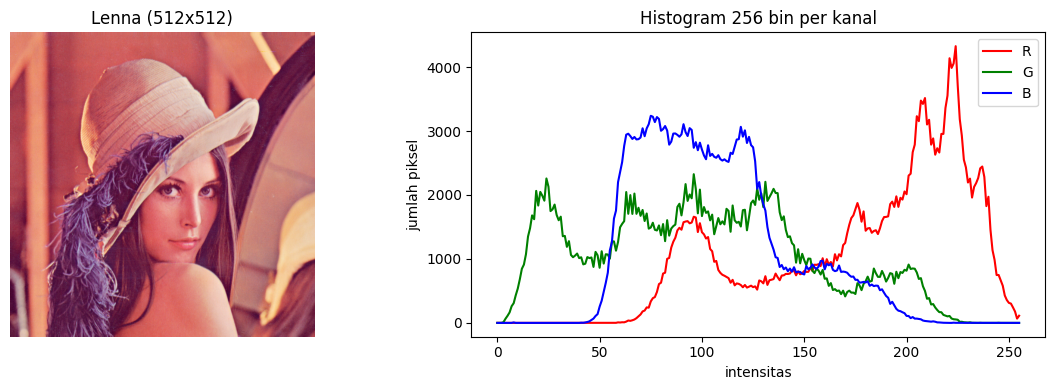

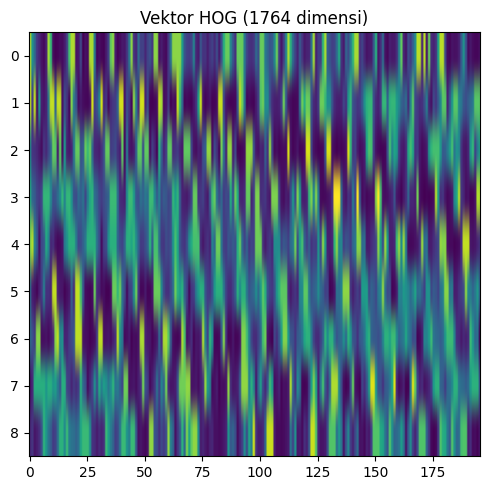

In [8]:
# ---- visualisasi ----
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].imshow(arr)
axes[0].set_title("Lenna (512x512)")
axes[0].axis("off")
for name, color in (("R", "red"), ("G", "green"), ("B", "blue")):
    axes[1].plot(hist[name], color=color, label=name)
axes[1].set_title("Histogram 256 bin per kanal")
axes[1].set_xlabel("intensitas")
axes[1].set_ylabel("jumlah piksel")
axes[1].legend()
fig.tight_layout()
fig.savefig(OUT / "histogram_rgb.png", dpi=120)

fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(hog_vec.reshape(9, -1), aspect="auto", cmap="viridis")
ax.set_title(f"Vektor HOG ({hog_vec.shape[0]} dimensi)")
fig.tight_layout()
fig.savefig(OUT / "hog.png", dpi=120)
print("grafik -> output/histogram_rgb.png, output/hog.png")
print("\nSelesai praktikum 4.")